# Flight Price Data: Overview and Cleaning

**Goal:** load the scraped flight-price dataset, check its structure, data types and completeness, and prepare it for modelling the question *"should a traveller buy a ticket now or wait for a lower price?"*

**Contents**
1. Data loading
2. Labelling and policy evaluation
3. Data quality checks
4. Coverage analysis
5. Saving the dataset for modelling


## About

- **Label.** `wait = 1` if any later price in the look-ahead window (3–20 days, depending on how far out the flight is) is at least **3% below** the current price. 12.97M labelled rows from 1.07M itineraries, departures Jul 2025 – Apr 2026.
- **Always Waiting usually loses.**  −3% (61–90 days) to −22% (8–14 days) on average versus buying now. Perfect hindsight would save only 3.7–7.7%.
- **Waiting is right 18–37% of the time**, more often the further away the departure.
- **Limitation:** labels under-count drops for sparsely scraped flights (wait rate rises with the number of observed future prices, even within a horizon bucket).

In [1]:
import datetime
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

lowess = sm.nonparametric.lowess
warnings.filterwarnings("ignore")

## 1. Data loading and feature engineering

In [3]:
import re
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd

MIN_DTD = 2                                  # skip the departure day itself
BUCKETS = np.array([3, 7, 14, 30, 60, 90])   # days-to-departure buckets
WINDOW_N = np.array([3, 5, 7, 10, 16, 20])   # look-ahead window length per bucket (days)
MIN_OBS_PER_ITIN = 5
X_DROP = 0.03                

DEP_FROM = "2025-07-01"                      # first departure date in the analysis
DEP_TO = "2026-05-01"                        # exclusive upper bound for departure dates

_TIME_RE = re.compile(r"T\d{2}:\d{2}:\d{2}")


def _norm_id(s):
    return _TIME_RE.sub("", s) if s else s


def _connect(db_path: str) -> sqlite3.Connection:
    con = sqlite3.connect(db_path)
    con.create_function("norm_id", 1, _norm_id, deterministic=True)
    con.execute("PRAGMA cache_size = -200000")
    return con


def build_flights(con) -> pd.DataFrame:
    """itin + legs -> one row per itinerary leg."""
    itin = pd.read_sql_query(
        "SELECT itinerary_id, departure_date, region_from, region_to, is_best FROM itin", con)
    legs = pd.read_sql_query(
        """SELECT itinerary_id, airline_code, flight_number, airline_name, aircraft, src, dst,
                  departure_datetime, arrival_datetime, travel_time, emissions
           FROM legs""", con)

    flights = itin.merge(legs, on="itinerary_id", how="inner")
    flights["itinerary_id"] = flights["itinerary_id"].str.replace(_TIME_RE, "", regex=True)
    flights = flights.drop_duplicates(subset=["itinerary_id", "src", "dst"], keep="last")

    for c in ["departure_datetime", "arrival_datetime"]:
        flights[c] = pd.to_datetime(flights[c].str.replace(" ", "T"), format="mixed")
    flights["departure_date"] = pd.to_datetime(flights["departure_date"], errors="coerce")
    return flights


def load_prices(con, valid_ids: set, chunksize=500_000) -> pd.DataFrame:
    """Stream prices, keeping only itineraries that exist in the flights table."""
    parts = []
    for chunk in pd.read_sql_query(
            "SELECT norm_id(itinerary_id) AS itinerary_id, price_datetime, price "
            "FROM prices WHERE price > 0", con, chunksize=chunksize):
        chunk = chunk[chunk["itinerary_id"].isin(valid_ids)]
        chunk["price"] = chunk["price"].astype("float32")
        parts.append(chunk)

    prices = pd.concat(parts, ignore_index=True)
    prices["price_datetime"] = pd.to_datetime(
        prices["price_datetime"].str.replace(" ", "T"), format="mixed")
    return prices


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    dep, pr = df["departure_datetime"], df["price_datetime"]
    df["days_to_departure"] = (dep.dt.normalize() - pr.dt.normalize()).dt.days
    df["flight_number"] = df["airline_code"].astype(str) + df["flight_number"].astype(str).str.strip()
    for c in ["airline_code", "flight_number", "airline_name", "aircraft",
              "src", "dst", "region_from", "region_to"]:
        df[c] = df[c].astype("category")
    
    return df




def prepare(db_path="../scraper/flights.db", cache="flights_clean.parquet", force=False) -> pd.DataFrame:
    """Build the cleaned price table from the raw SQLite database (cached as parquet)."""
    if Path(cache).exists() and not force:
        return pd.read_parquet(cache)

    con = _connect(db_path)
    flights = build_flights(con)
    prices = load_prices(con, set(flights["itinerary_id"]))
    df = prices.merge(flights, on="itinerary_id", how="inner")
    df = add_features(df)
    con.close()

    df.to_parquet(cache, index=False)
    return df


def daily_prices(df: pd.DataFrame) -> pd.DataFrame:
    """One price per itinerary and scrape day, with days-to-departure.
    Drops itineraries with less than MIN_OBS_PER_ITIN observations."""
    d = df[["itinerary_id", "price_datetime", "price", "departure_date"]].copy()
    d["day"] = d["price_datetime"].dt.normalize()
    d = d.sort_values("price_datetime").drop_duplicates(["itinerary_id", "day"], keep="last")

    n_obs = d.groupby("itinerary_id")["day"].transform("size")
    before = d["itinerary_id"].nunique()
    d = d[n_obs >= MIN_OBS_PER_ITIN]
    print(f"Itineraries dropped (< {MIN_OBS_PER_ITIN} observations): "
          f"{before - d['itinerary_id'].nunique():,} of {before:,}")

    d["dtd"] = (d["departure_date"] - d["day"]).dt.days
    d = d[d["dtd"].between(0, BUCKETS.max())]
    return d


def price_matrix_for(df, dep_from=DEP_FROM, dep_to=DEP_TO):
    """Itinerary x days-to-departure price matrix, same rows as filter_for_cold_start."""
    d = daily_prices(df)
    dep = d["departure_date"]
    d = d[(dep >= dep_from) & (dep < dep_to) & (dep <= pd.Timestamp.now().normalize())].copy()

    d["code"], names = pd.factorize(d["itinerary_id"])
    M = np.full((d["code"].max() + 1, BUCKETS.max() + 1), np.nan, dtype="float32")
    M[d["code"].to_numpy(), d["dtd"].to_numpy()] = d["price"].to_numpy(dtype="float32")
    code_of = pd.Series(np.arange(len(names)), index=names)
    return M, code_of

def add_price_features(d: pd.DataFrame) -> pd.DataFrame:
    # price features
    d = d.sort_values(["itinerary_id", "price_datetime"]).copy()
    g = d.groupby("itinerary_id", sort=False)
    p = d["price"]

    d["chg_1_%"] = (p /g["price"].shift(1) - 1) * 100
    d['vs-min_so_far_%'] = (p / g["price"].cummin() - 1) * 100
    
    abs_chg = d["chg_1_%"].abs().fillna(0)
    n_moves = g.cumcount()                                         # number of past changes
    d["mean_abs_chg_so_far"] = abs_chg.groupby(d["itinerary_id"], sort=False).cumsum() / n_moves.replace(0, np.nan)
    return d



def filter_for_cold_start(df: pd.DataFrame, dep_from=DEP_FROM, dep_to=DEP_TO,
                          x_drop=X_DROP, spike_ratio=3.0) -> pd.DataFrame:
    """wait = 1 if the lowest later price in the window is at least x_drop below the current price.
    cost_wait = what a waiting buyer pays: first price <= target, else the last price in the window."""
    d = daily_prices(df)
    last_day = d["day"].max()

    dep = d["departure_date"]
    d = d[(dep >= dep_from) & (dep < dep_to) & (dep <= pd.Timestamp.now().normalize())].copy()

    # remove spikes BEFORE the matrix, so window_min never picks a glitch
    spikes = flag_spikes(d, ratio=spike_ratio).reindex(d.index)
    print(f"Spike rows removed: {int(spikes.sum()):,}")
    d = d[~spikes].reset_index(drop=True)

    d["code"], _ = pd.factorize(d["itinerary_id"])
    M = np.full((d["code"].max() + 1, BUCKETS.max() + 1), np.nan, dtype="float32")
    M[d["code"].to_numpy(), d["dtd"].to_numpy()] = d["price"].to_numpy(dtype="float32")

    ex = d[d["dtd"] >= MIN_DTD].copy()
    c, t = ex["code"].to_numpy(), ex["dtd"].to_numpy()
    p = ex["price"].to_numpy(dtype="float32")
    idx = np.searchsorted(BUCKETS, t)
    N = WINDOW_N[idx]
    target = p * (1 - x_drop)

    best = np.full(len(c), np.inf, dtype="float32")    # lowest later price (oracle)
    hit = np.full(len(c), np.nan, dtype="float32")     # first later price <= target
    last = np.full(len(c), np.nan, dtype="float32")    # last later price in window
    n_future = np.zeros(len(c), dtype="int16")

    for k in range(1, N.max() + 1):
        p_k = M[c, np.maximum(t - k, 0)]
        ok = (k <= N) & (k <= t) & ~np.isnan(p_k)
        best = np.minimum(best, np.where(ok, p_k, np.inf))
        last = np.where(ok, p_k, last)
        n_future += ok
        new_hit = ok & np.isnan(hit) & (p_k <= target)
        hit[new_hit] = p_k[new_hit]

    ex["bucket"] = BUCKETS[idx]
    ex["window_N"] = N
    ex["n_future"] = n_future
    ex["window_min"] = np.where(np.isfinite(best), best, np.nan)
    ex["cost_wait"] = np.where(np.isnan(hit), last, hit)
    ex["wait"] = (~np.isnan(hit)).astype("int8")

    # drop: window runs past last scraped day, or no later price at all
    window_end = ex["day"] + pd.to_timedelta(np.minimum(N, t), unit="D")
    ex = ex[(window_end <= last_day).to_numpy() & (n_future > 0)]
    
    # drop spike rows, as they are probably fare switches 
    bad = (ex["price"] > 3 * ex["window_min"]) | (ex["cost_wait"] > 3 * ex["price"])
    print(f"fare-switch rows dropped: {bad.sum():,}")
    ex = ex[~bad].reset_index(drop=True)

    # drop n_future==1, as they are the noziest and least useful for training
    print(f"n_future==1 rows dropped: {(ex['n_future'] == 1).sum():,}")
    ex = ex[ex["n_future"] > 1].reset_index(drop=True)
    ex = add_price_features(ex)

    print(ex.groupby("bucket")["wait"].agg(examples="size", wait_rate="mean").round(3).to_string())

    print('-'*25 +'\n'+ f"Final rows: {len(ex):,}, itineraries: {ex['itinerary_id'].nunique():,}")

    return ex.drop(columns=["code"]).reset_index(drop=True)

def flag_spikes(d, ratio=3.0, window=7, min_periods=4):
    """True where a price is far above or below the median of the same itinerary's nearby scrapes."""
    d = d.sort_values(["itinerary_id", "dtd"], ascending=[True, False])
    med = d.groupby("itinerary_id")["price"].transform(
        lambda s: s.rolling(window, center=True, min_periods=min_periods).median())
    return (d["price"] > ratio * med) | (d["price"] < med / ratio)



In [4]:
# Rebuild the cleaned dataset from the raw database (force=True ignores the cache)
df = prepare(db_path="../scraper/flights.db", cache="flights_clean.parquet", force=False)

## 2. Labelling and policy evaluation

In [5]:
# Label observations for departures in [DEP_FROM, DEP_TO), at least 2 days before departure
ex = filter_for_cold_start(df)
ex_filtered = ex

Itineraries dropped (< 5 observations): 677,750 of 1,967,106
Spike rows removed: 39,954
fare-switch rows dropped: 127,362
n_future==1 rows dropped: 2,731,550
        examples  wait_rate
bucket                     
3         223465      0.178
7        1576440      0.215
14       1634662      0.247
30       3287710      0.276
60       3451272      0.315
90       2799972      0.366
-------------------------
Final rows: 12,973,521, itineraries: 1,066,559


Of 1.97M itineraries, 678k with fewer than 5 scrape days were dropped. Then:

- 40k **spikes** prices were removed (more than 3× off the median of nearby scrapes)
- 127k rows were dropped as likely **fare-class switches**, but it can be other reasons (scraping error, etc.)
- 2.73M rows with only **one** future price in their window were dropped


In [20]:
cur = ex["price"].astype("float64")
ex["save_oracle_%"] = 100 * (cur - np.minimum(ex["window_min"], cur)) / cur
ex["save_wait_%"] = 100 * (cur - ex["cost_wait"]) / cur        # always wait, realistic

print(ex.groupby("bucket").agg(
    rows=("wait", "size"),
    wait_share=("wait", "mean"),
    oracle_mean=("save_oracle_%", "mean"),
    always_wait_mean=("save_wait_%", "mean"),
    always_wait_median=("save_wait_%", "median"),
).round(2).to_string())

# leak check: does the label just follow scrape density?
print(pd.crosstab(ex["bucket"], ex["n_future"].clip(upper=6),
                  values=ex["wait"], aggfunc="mean").round(2))

           rows  wait_share  oracle_mean  always_wait_mean  always_wait_median
bucket                                                                        
3        223465        0.18         3.70            -11.34               -0.39
7       1576440        0.21         4.56            -18.16              -10.39
14      1634662        0.25         5.19            -22.27              -14.86
30      3287710        0.28         5.63            -15.90               -6.45
60      3451272        0.31         6.56            -10.71               -0.17
90      2799972        0.37         7.74             -2.98                0.00
n_future     2     3     4     5     6
bucket                                
3         0.18   NaN   NaN   NaN   NaN
7         0.18  0.21  0.24  0.24   NaN
14        0.17  0.23  0.27  0.27  0.28
30        0.20  0.24  0.28  0.33  0.34
60        0.26  0.30  0.33  0.33  0.37
90        0.31  0.34  0.38  0.40   NaN


In [22]:
print(ex.nlargest(10, "save_oracle_%")[["itinerary_id", "price", "window_min", "save_oracle_%"]].round(1))


                       itinerary_id       price  window_min  save_oracle_%
355782     BA484-2025-08-15-LHR-BCN  490.899994  163.600006           66.7
4461442   HV6334-2025-09-08-VLC-AMS  195.000000   65.000000           66.7
4573950   HV6334-2025-09-08-VLC-AMS  195.000000   65.000000           66.7
4801803   HV6334-2025-09-08-VLC-AMS  195.000000   65.000000           66.7
4817175   HV6336-2025-09-19-VLC-AMS  195.000000   65.000000           66.7
9053193   EI3272-2025-11-06-DUB-BHX   54.000000   18.000000           66.7
9579303   IB1882-2025-11-01-DUB-MAD  123.000000   41.000000           66.7
9785335   IB1882-2025-11-01-DUB-MAD  123.000000   41.000000           66.7
9826162    BA829-2025-12-12-DUB-LHR  195.000000   65.000000           66.7
10074099  IB1882-2025-11-01-DUB-MAD  123.000000   41.000000           66.7


**What the policies show**
- **Perfect hindsight** (buy at the window minimum) saves 3.7% at 2–3 days and up to 7.7% at 61–90 days
- **Always wait** loses on average at every horizon: −11% (2–3 days), −22% (8–14 days), −3% (61–90 days). Waiting into the last week before departure is the most expensive mistake.
- **Density check:** within each bucket, the wait rate rises with the number of observed future prices (e.g. 0.17 → 0.28 at 8–14 days). Part of this is mechanical: a drop on a day the scraper did not visit is invisible. The labels are therefore conservative for sparsely scraped flights.

In [23]:
ex["airline"] = ex["itinerary_id"].map(
    df.drop_duplicates("itinerary_id").set_index("itinerary_id")["airline_code"].astype(str))

# saving if we wait and buy at the lowest price in the window; 0 otherwise
ex["saving_pct"] = np.where(ex["wait"] == 1,
                            100 * (ex["price"] - ex["window_min"]) / ex["price"], 0)


res = ex.groupby("airline").agg(
    rows=("wait", "size"),
    itins=("itinerary_id", "nunique"),
    wait_share=("wait", "mean"),
    saving_mean=("saving_pct", "mean"),
)
res = res[res["itins"] >= 50].sort_values("saving_mean", ascending=False)
print(res.round(2).to_string())

            rows   itins  wait_share  saving_mean
airline                                          
F9        117040   10737        0.50        13.03
LS         28079    2232        0.60        12.63
RK         23726    2027        0.56        12.50
FR        996776   83304        0.53        11.74
I2         33088    2747        0.42        11.58
GQ         61524    5225        0.46        11.34
A3        211602   16495        0.39        10.07
W9         17352    1197        0.57         9.92
W6        132569   10855        0.53         9.89
VY        347782   27251        0.45         9.62
W4         52481    4214        0.51         9.61
NK         52337    5291        0.40         8.67
HV         52937    4000        0.48         8.36
B6         60176    5950        0.35         7.79
UX        169215   13621        0.33         7.64
SK        841645   68307        0.27         7.29
WN         63953    6479        0.34         7.08
TP        430440   34606        0.31         6.84


**Airline differences.** Low-cost carriers drop prices much more often: LS 0.60, RK 0.56, FR 0.53, W6 0.53, F9 0.50. Network carriers sit around 0.20–0.25 (LH, KL, AF, BA, AA, DL), and LO (0.17), VS (0.15) and AZ (0.14) are the lowest among large samples. Mean oracle savings follow the same order (FR 11.7%, LH 4.0%). Airline is the strongest single predictor found so far.

In [24]:
g = ex.groupby(["bucket", "wait"])["save_wait_%"].mean().unstack()
g.columns = ["avg_if_wrong_%", "avg_if_right_%"]
g["break_even_precision"] = -g["avg_if_wrong_%"] / (g["avg_if_right_%"] - g["avg_if_wrong_%"])
print(g.round(2))

        avg_if_wrong_%  avg_if_right_%  break_even_precision
bucket                                                      
3               -17.86           18.79                  0.49
7               -28.09           18.16                  0.61
14              -35.38           17.72                  0.67
30              -28.42           16.98                  0.63
60              -23.62           17.39                  0.58
90              -14.66           17.25                  0.46


A wrong "wait" costs 15–35% on average, a correct one saves about 17–19%. To save money, a model's "wait" calls must be right at least 46% (61–90 days) to 67% (8–14 days) of the time. Accuracy and F1 are therefore not useful metrics here: the model should be evaluated by **% saved**, with its decision threshold tuned on that.

## 3. Data quality checks

In [6]:
print("Data Statistics:")
print(ex.columns)
print(ex.dtypes)

print(f"Total price records: {len(ex):,}")
print(f"Total itineraries: {ex['itinerary_id'].nunique():,}")

# Duplicate rows

dup = ex[ex.duplicated(keep=False)]
print(f"Rows involved in duplication: {len(dup):,}")
print(f"Extra copies (what drop_duplicates would remove): {ex.duplicated().sum():,}")
print(dup.sort_values(list(ex.columns[:3])).head(20))
# Remove exact duplicate rows
ex = ex.drop_duplicates(keep="last")

# Missing and zero values
print("Missing values per column:")
print(ex.isnull().sum())
print("Zero values per column:")
print((ex == 0).sum())

# Price observations per itinerary
print("Price records per itinerary:")
print(ex.groupby("itinerary_id").size().describe())

Data Statistics:
Index(['itinerary_id', 'price_datetime', 'price', 'departure_date', 'day',
       'dtd', 'bucket', 'window_N', 'n_future', 'window_min', 'cost_wait',
       'wait', 'chg_1_%', 'vs-min_so_far_%', 'mean_abs_chg_so_far'],
      dtype='object')
itinerary_id                   object
price_datetime         datetime64[ns]
price                         float32
departure_date         datetime64[ns]
day                    datetime64[ns]
dtd                             int64
bucket                          int64
window_N                        int64
n_future                        int16
window_min                    float32
cost_wait                     float32
wait                             int8
chg_1_%                       float32
vs-min_so_far_%               float32
mean_abs_chg_so_far           float64
dtype: object
Total price records: 12,973,521
Total itineraries: 1,066,559
Rows involved in duplication: 0
Extra copies (what drop_duplicates would remove): 0
Empty DataFra

## 4. Coverage analysis

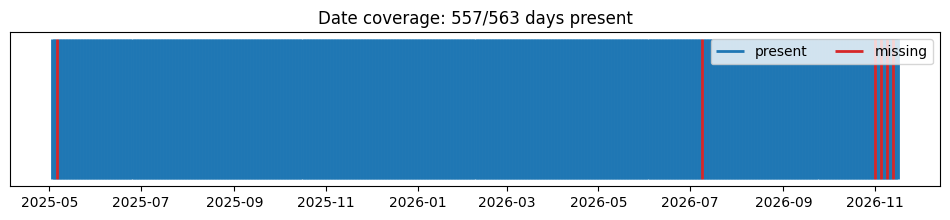

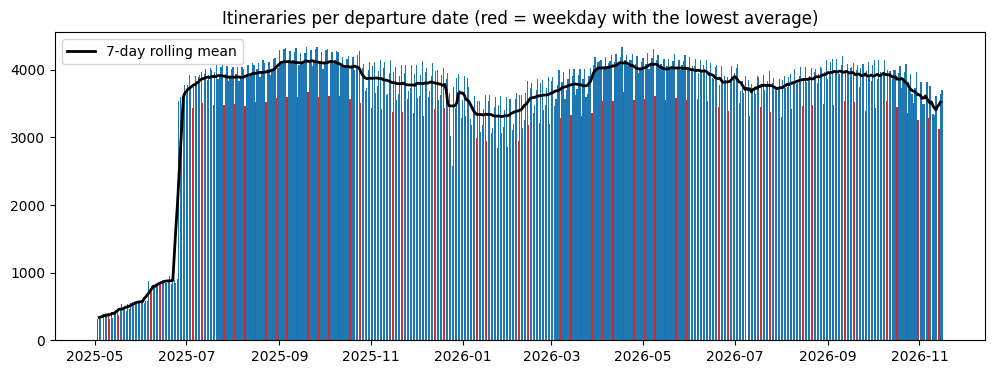

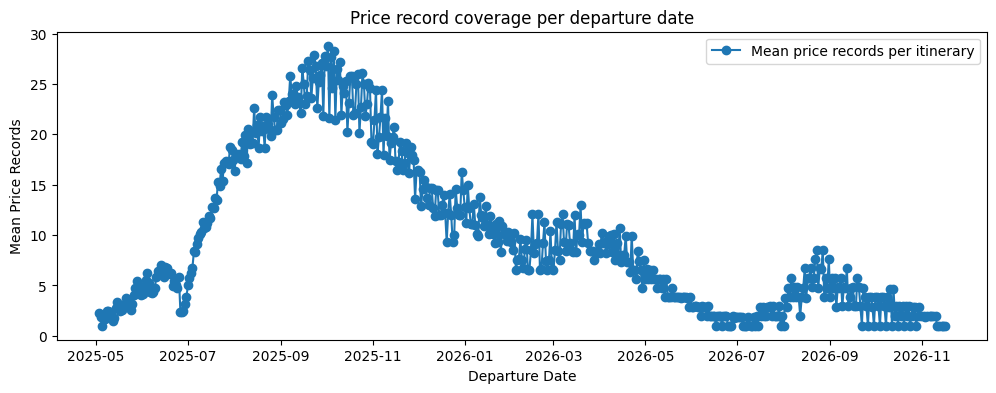

In [26]:
dates = df["departure_date"].dropna().unique()

full_range = pd.date_range(dates.min(), dates.max(), freq="D")
present = full_range.isin(dates)

fig, ax = plt.subplots(figsize=(12, 2))
ax.vlines(full_range[present], 0, 1, color="tab:blue", lw=2, label="present")
ax.vlines(full_range[~present], 0, 1, color="tab:red", lw=2, label="missing")
ax.set_yticks([])
ax.set_title(f"Date coverage: {present.sum()}/{len(full_range)} days present")
ax.legend(loc="upper right", ncol=2)
plt.show()

itin_per_date = df.groupby("departure_date")["itinerary_id"].nunique()
itin_per_date.index = pd.to_datetime(itin_per_date.index)

# full range so missing days show as gaps, not interpolated lines
full_range = pd.date_range(itin_per_date.index.min(), itin_per_date.index.max(), freq="D")
s = itin_per_date.reindex(full_range)

fig, ax = plt.subplots(figsize=(12, 4))
colors = ["tab:red" if d.weekday() == s.groupby(s.index.weekday).mean().idxmin() else "tab:blue"
          for d in s.index]
ax.bar(s.index, s.values, color=colors, width=0.8)
ax.plot(s.index, s.rolling(7, min_periods=4, center=True).mean(),
        color="black", lw=2, label="7-day rolling mean")
ax.set_title("Itineraries per departure date (red = weekday with the lowest average)")
ax.legend()
plt.show()


# compare mean number of price records per itinerary on each departure date
records_per_itin = df.groupby("departure_date")["itinerary_id"].value_counts().groupby("departure_date").mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(records_per_itin.index, records_per_itin.values, marker="o", color="tab:blue", label="Mean price records per itinerary")
ax.set_title("Price record coverage per departure date")
ax.set_xlabel("Departure Date")
ax.set_ylabel("Mean Price Records")
ax.legend()
plt.show()

In [29]:
d = df[["itinerary_id", "price_datetime", "departure_date"]].copy()
d["day"] = d["price_datetime"].dt.normalize()
d = d.drop_duplicates(["itinerary_id", "day"])

summary = pd.DataFrame({
    "n": d.groupby("itinerary_id").size(),
    "dep": d.groupby("itinerary_id")["departure_date"].first(),
})
summary["dep_month"] = summary["dep"].dt.to_period("M")
rows_per = summary["n"]
for lo in [1, 3, 5, 10, 15, 25]:
    keep = summary[summary["n"] >= lo]
    kept = rows_per[rows_per >= lo]
    print(f"min {lo}: {len(keep):,} of {len(summary):,} itineraries kept")
    print(f"min {lo}: rows kept {kept.sum():,} of {rows_per.sum():,} ({100 * kept.sum() / rows_per.sum():.1f}%)")


min 1: 1,967,106 of 1,967,106 itineraries kept
min 1: rows kept 20,428,079 of 20,428,079 (100.0%)
min 3: 1,601,632 of 1,967,106 itineraries kept
min 3: rows kept 19,866,656 of 20,428,079 (97.3%)
min 5: 1,289,356 of 1,967,106 itineraries kept
min 5: rows kept 18,783,935 of 20,428,079 (92.0%)
min 10: 856,847 of 1,967,106 itineraries kept
min 10: rows kept 15,771,759 of 20,428,079 (77.2%)
min 15: 535,324 of 1,967,106 itineraries kept
min 15: rows kept 12,001,482 of 20,428,079 (58.7%)
min 25: 183,836 of 1,967,106 itineraries kept
min 25: rows kept 5,025,253 of 20,428,079 (24.6%)


**Daily volume.** The scraper ramped up from about 300 itineraries a day in May 2025 to about 4,000 by July 2025 and stayed near that level, with dips in late 2025 and January 2026. Records per itinerary vary by departure date, so labels for thinly covered periods are less reliable.

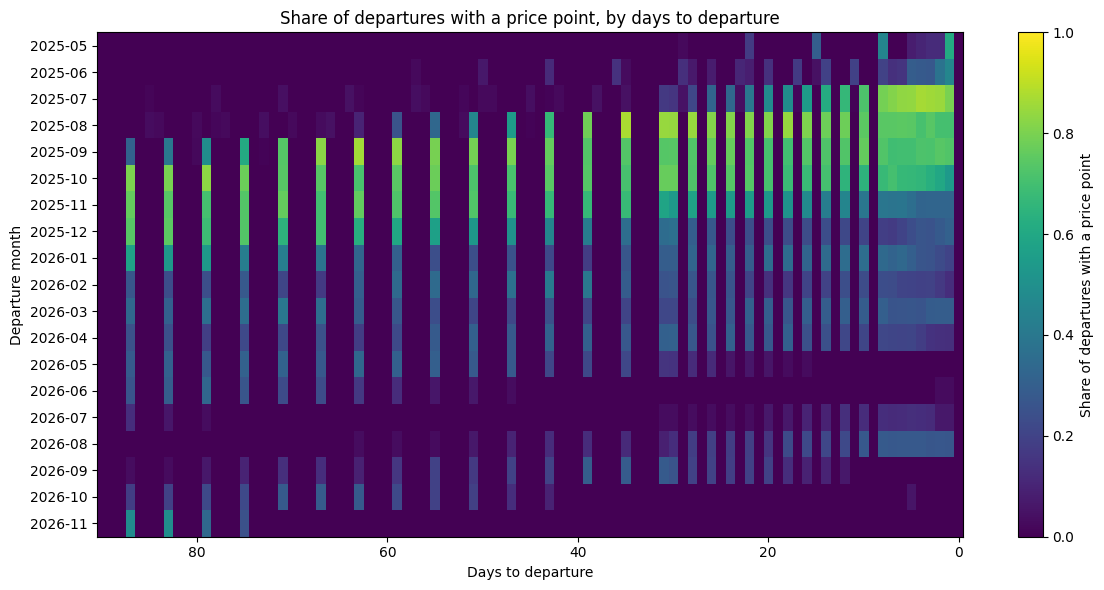

In [6]:
MAX_DTD = 90

# Share of departures that have a price point at each days_to_departure, per departure month
d_all = df[["itinerary_id", "days_to_departure", "departure_date"]]
d_all = d_all[d_all["days_to_departure"].between(0, MAX_DTD)].drop_duplicates(["itinerary_id", "days_to_departure"]).copy()
d_all["dep_month"] = d_all["departure_date"].dt.to_period("M")

n_per_month = d_all.groupby("dep_month")["itinerary_id"].nunique()
cnt = (d_all.groupby(["dep_month", "days_to_departure"])["itinerary_id"]
            .nunique().unstack(fill_value=0)
            .reindex(columns=range(MAX_DTD + 1), fill_value=0))
share = cnt.div(n_per_month, axis=0)

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(share.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.invert_xaxis()
ax.set_yticks(range(len(share)))
ax.set_yticklabels(share.index.astype(str))
ax.set_xlabel("Days to departure")
ax.set_ylabel("Departure month")
ax.set_title("Share of departures with a price point, by days to departure")
plt.colorbar(im, label="Share of departures with a price point")
plt.tight_layout()
plt.show()

**Monthly coverage.** The heatmap shows, for each departure month, the share of flights that have a price point at each distance from departure (days to departure). Use it to spot months or distances with gaps before reading the policy results.

In [7]:
# Scraping windows to evaluate (adjust as needed)
EDGES = [0, 4, 8, 15, 31, 46, 61, 91]   # bins: [0-3], [4-7], [8-14], [15-30], [31-45], [46-60], [61-90]
LABELS = ["0-3", "4-7", "8-14", "15-30", "31-45", "46-60", "61-90"]

# Unique (departure, DTD) points
d = df[["itinerary_id", "days_to_departure"]].drop_duplicates()
d = d[d["days_to_departure"].between(0, 90)]
d["win"] = pd.cut(d["days_to_departure"], EDGES, right=False, labels=LABELS)

# Departure x window matrix: number of price points per window
all_ids = df["itinerary_id"].unique()
cnt = (pd.crosstab(d["itinerary_id"], d["win"])
         .reindex(all_ids, fill_value=0)[LABELS])

n_itin, n_pts = len(cnt), int(cnt.values.sum())
print(f"Departures: {n_itin:,}, price points (0-90 DTD): {n_pts:,}\n")

# 1) Bottleneck: share of departures with >= 1 and >= 2 points in each window
cov = pd.DataFrame({"≥1": (cnt >= 1).mean(), "≥2": (cnt >= 2).mean(), "median points": cnt.median()})
print(cov.round(3), "\n")

# 2) Data retained when requiring >= m points in each of the first k windows (counting from 0 days)
rows = []
for k in range(1, len(LABELS) + 1):
    for m in (1, 2, 3):
        ok = (cnt.iloc[:, :k] >= m).all(axis=1)
        rows.append({
            "window": f"0-{EDGES[k]-1}",
            "min points/window": m,
            "departures": int(ok.sum()),
            "% departures": round(100 * ok.mean(), 1),
            "points": int(cnt[ok].values.sum()),
            "% points": round(100 * cnt[ok].values.sum() / n_pts, 1),
        })
res = pd.DataFrame(rows)
print(res.pivot(index="window", columns="min points/window", values=["% departures", "% points"]))

Departures: 1,967,106, price points (0-90 DTD): 20,407,176

          ≥1     ≥2  median points
win                               
0-3    0.471  0.282            0.0
4-7    0.537  0.349            1.0
8-14   0.576  0.346            1.0
15-30  0.694  0.557            2.0
31-45  0.592  0.354            1.0
46-60  0.594  0.353            1.0
61-90  0.701  0.531            2.0 

                  % departures             % points            
min points/window            1     2     3        1     2     3
window                                                         
0-14                      32.3  18.7   6.3     59.3  39.9  12.7
0-3                       47.1  28.2  12.2     71.2  50.3  22.8
0-30                      30.4  17.4   5.5     58.0  38.6  11.9
0-45                      25.7  14.2   2.9     52.6  33.7   7.6
0-60                      21.4  11.4   2.2     45.8  28.3   6.0
0-7                       37.5  21.9   8.0     63.6  43.3  15.3
0-90                      18.4   8.9   1.7     

**Coverage by window.** Only 47 to 70% of departures have at least one price point in each window, and 28 to 56% have two or more. Requiring at least one point in every window from 0 to 90 days keeps 18% of departures; requiring two keeps 9%. Keeping only the 0 to 14 day windows with one point each keeps 32% of departures and 59% of price points. This is the trade-off between sample size and coverage that the modelling step has to resolve.

# 5. Saving dataset for model

In [10]:
ex.columns

Index(['itinerary_id', 'price_datetime', 'price', 'departure_date', 'day',
       'dtd', 'bucket', 'window_N', 'n_future', 'window_min', 'cost_wait',
       'wait', 'chg_1_%', 'vs-min_so_far_%', 'mean_abs_chg_so_far'],
      dtype='object')

In [12]:
#1. Labelled observations
PRICE_FEATS = ["chg_1_%",
               "vs-min_so_far_%", "mean_abs_chg_so_far"]
labelled = ex[["itinerary_id", "price_datetime", "price", "departure_date", "dtd", "bucket",
               "window_N", "n_future", "wait", "cost_wait", "window_min"] + PRICE_FEATS]

# 2. Flight features 
feat_cols = ["itinerary_id", "price_datetime", "airline_name", "flight_number", "aircraft",
             "src", "dst", "region_from", "region_to", "travel_time", "emissions", "departure_datetime"]
features = df[feat_cols].drop_duplicates(["itinerary_id", "price_datetime"]).copy()

dep_dt = features["departure_datetime"]
features["dep_hour"] = dep_dt.dt.hour.astype("int8")
features["dep_dayofweek"] = dep_dt.dt.dayofweek.astype("int8")   # 0 = Monday
features["dep_month"] = dep_dt.dt.month.astype("int8")
features["is_weekend"] = (features["dep_dayofweek"] >= 5).astype("int8")
features["season"] = ((dep_dt.dt.month % 12) // 3).astype("int8")  # 0 = Dec-Feb, 1 = Mar-May, 2 = Jun-Aug, 3 = Sep-Nov
features = features.drop(columns="departure_datetime")

# 3. Join and check that no rows were gained or lost
model_df = labelled.merge(features, on=["itinerary_id", "price_datetime"], how="left")
assert len(model_df) == len(labelled), "join changed the row count"

# 5. Save the model
model_df.to_parquet("model_dataset.parquet", index=False)